# 02 · Sequence embeddings (ProtBert)
**Question.** Does a protein language model recover the ABHD / non-ABHD structure of the superfamily?
**Inputs.** `data/derived/protbert.npz` (mean-pooled ProtBert embeddings, 1024-d, one per UniProt entry).
**Caveats.** Sequences > 510 residues are truncated; the mean includes `[CLS]`/`[SEP]`; isoforms/fragments are embedded as-is.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path; sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> ../src
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from abhd import config as C, data as D, plots as P
pd.set_option("display.width", 160, "display.max_colwidth", 60)
meta = D.load_entries()

In [2]:
accs, X = D.load_protbert()
pb = D.cosine_matrix(X, accs)
v = pb.values[np.triu_indices(len(accs), 1)]
print("cosine distance between all pairs, quantiles (0, 1%, 10%, 50%, 90%, 100%):", np.quantile(v, [0, .01, .1, .5, .9, 1]).round(3))

cosine distance between all pairs, quantiles (0, 1%, 10%, 50%, 90%, 100%): [0.    0.018 0.058 0.124 0.261 0.716]


**Reading this.** Cosine distances are compressed into a narrow range (median ≈ 0.12): mean-pooled embeddings of related
proteins all look alike, so absolute values mean little and only ranks are informative.

## Nearest neighbours (reviewed entries only)

In [3]:
for g in ["ABHD2", "ABHD14B"]:
    print(g); display(D.nearest(pb, D.reviewed_accession(meta, g), meta, 8).round(3))

ABHD2


,distance,gene,reviewed
Q8WU67,0.028,ABHD3,True
Q9NZD8,0.048,SPG21,True
P06858,0.050,LPL,True
O95870,0.052,ABHD16A,True
Q86WA6,0.055,BPHL,True
Q0P651,0.057,ABHD18,True
Q9Y570,0.058,PPME1,True
Q9BV23,0.060,ABHD6,True


ABHD14B


,distance,gene,reviewed
Q9BUJ0,0.043,ABHD14A,True
Q96I13,0.048,ABHD8,True
Q8NFV4,0.049,ABHD11,True
Q8NCC3,0.052,PLA2G15,True
Q86WA6,0.057,BPHL,True
Q99685,0.063,MGLL,True
O95870,0.071,ABHD16A,True
Q96GS6,0.075,ABHD17A,True


## 2-D maps

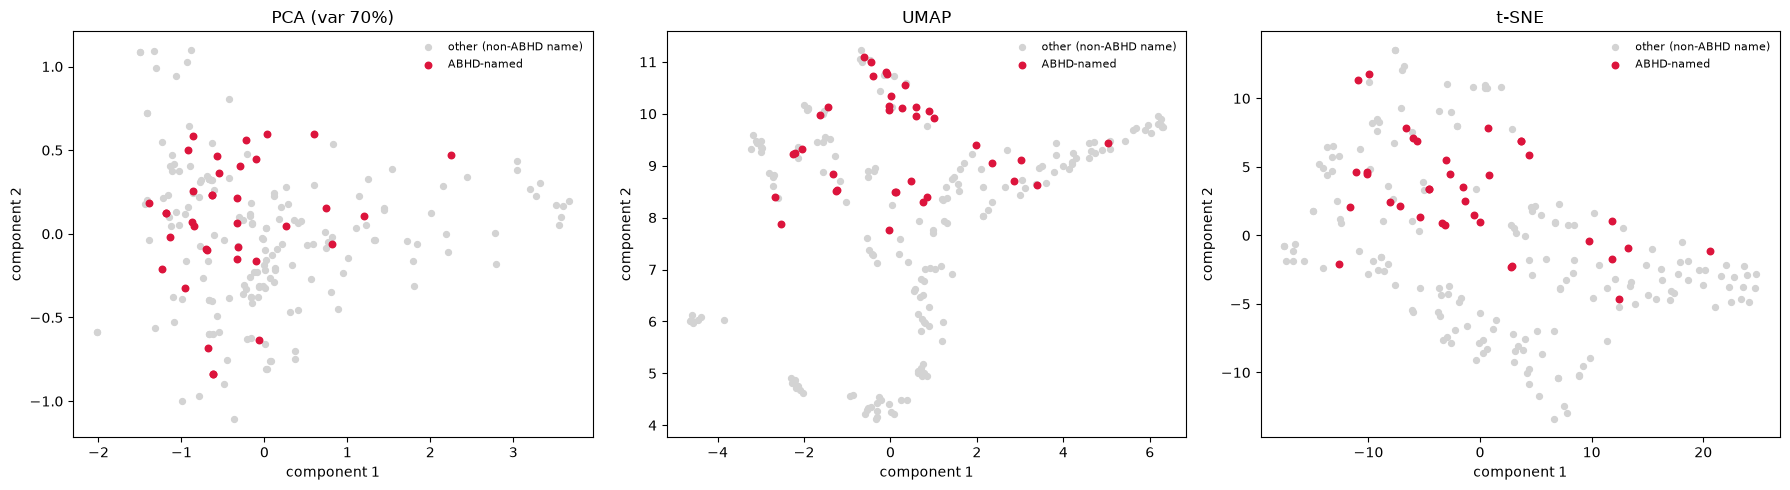

In [4]:
m = meta.loc[accs]
is_abhd = m.abhd_named.values; lab = m.gene_name.values
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
pca = PCA(2).fit(X); coords = {"PCA": pca.transform(X), "UMAP": D.umap_coords(X),
                               "t-SNE": TSNE(2, random_state=42, perplexity=30).fit_transform(X)}
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, (k, c) in zip(axs, coords.items()):
    P.scatter_abhd(c, lab, is_abhd, k + (f" (var {pca.explained_variance_ratio_.sum():.0%})" if k == "PCA" else ""), ax, annotate=False)
plt.tight_layout(); plt.show()
hover = [f"<b>{m.gene_name.iloc[i]}</b><br>{accs[i]}<br>{m.entry_name.iloc[i]}" for i in range(len(accs))]
P.interactive_scatter(coords["UMAP"], hover, {"other": (np.where(~is_abhd)[0], "lightgrey"),
                      "ABHD-named": (np.where(is_abhd)[0], "crimson")}, "ProtBert UMAP", "protbert_umap.html");

**Reading this.** Interactive version with hover text: `figures/protbert_umap.html`. If ABHD-named entries do not form their own
cluster in the UMAP, the name does not track sequence similarity. That is the point of the project, but the UMAP is a
qualitative picture (it depends on seed and `n_neighbors`); the neighbour tables above are the more reliable evidence.